In [ ]:
# region import
import numpy as np
import pandas as pd
from backtesting import Strategy, Backtest
import joblib
import talib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from backtesting import Backtest
# endregion

/Users/leoinv/Documents/CODE/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/leoinv/Documents/CODE/.venv/lib/python3.12/site-packages/backtesting/_plotting.py:55: UserWarning: Jupyter Notebook detected. Setting Bokeh output to notebook. This may not work in Jupyter clients without JavaScript support, such as old IDEs. Reset with `backtesting.set_bokeh_output(notebook=False)`.
  warnings.warn('Jupyter Notebook detected. '


Loading BokehJS ...

In [ ]:
class VolatilyTrigger(Strategy):
    # Parameters need to be tuned
    smooth_window = 200
    norm_lookback = 300
    
    # Constants parameters
    significance_level = 0.05
    lookback = norm_lookback // 3
    base_fraction = 0.2
    max_fraction = 0.8
    kelly_window = norm_lookback  

    def init(self):
        # --- indicators (unchanged) ---
        atr = self.I(talib.ATR, self.data.High, self.data.Low, self.data.Close, self.norm_lookback, plot=False)
        norm_range = self.I(lambda h, l, a: (np.log(h) - np.log(l)) / a,
                            self.data.High, self.data.Low, atr, plot=False)
        self.vola = self.I(talib.EMA, norm_range, self.smooth_window, plot=False)
        
        self.q05 = self.I(lambda v: pd.Series(v).rolling(self.lookback)
                          .quantile(self.significance_level).shift(1), self.vola, plot=False)
        self.q95 = self.I(lambda v: pd.Series(v).rolling(self.lookback)
                          .quantile(1 - self.significance_level).shift(1), self.vola, plot=False)

        self.last_below = -1
        self.curr_sig = 0

        # --- Kelly bookkeeping ---
        self.trade_results = []
        self._closed_seen = 0  

    def _record_new_closed_trades(self):
        """Capture newly-closed trades since last bar (Backtesting.py has no notify hooks)."""
        n_closed = len(self.closed_trades)
        if n_closed > self._closed_seen:
            new_trades = self.closed_trades[self._closed_seen:n_closed]
            for tr in new_trades:
                self.trade_results.append(tr.pl_pct)
            # keep rolling window for kelly
            if len(self.trade_results) > self.kelly_window:
                self.trade_results = self.trade_results[-self.kelly_window:]
            self._closed_seen = n_closed

    def _kelly_fraction(self):
        base_fraction = self.base_fraction
        if len(self.trade_results) < 5:
            return base_fraction
        wins = [r for r in self.trade_results if r > 0]
        losses = [-r for r in self.trade_results if r < 0]
        if not wins or not losses:
            return base_fraction
        W = len(wins) / len(self.trade_results)
        R = (sum(wins) / len(wins)) / (sum(losses) / len(losses))
        f_star = W - (1 - W) / R
        # Ensure it never drops below base_fraction unless Kelly says bigger
        return max(base_fraction, min(f_star, self.max_fraction))

    def next(self):        
        # 1 ─── Update Kelly stats
        self._record_new_closed_trades()

        # Get the latest index, hawkes value, and close price
        bar_idx = len(self.data) - 1
        v_now = self.vola[-1]
        close_now = self.data.Close[-1]

        # 2 ─── Reset signal if below lower quantile
        if v_now < self.q05[-1]:
            self.last_below = bar_idx
            self.curr_sig = 0

        # 3 ─── Detect breakout above upper quantile
        breakout_now = v_now > self.q95[-1]
        breakout_prev = self.vola[-2] <= self.q95[-2] if len(self.vola) >= 2 else False

        if breakout_now and breakout_prev and self.last_below > 0:
            # 4 ─── Determine direction from last low-vol point
            price_change = close_now - self.data.Close[self.last_below]
            self.curr_sig = 1 if price_change > 0 else -1

        # 5 ─── Position sizing (integer units only)
        size_fraction = self._kelly_fraction()
        units = int(self.equity * size_fraction / close_now)
        if units <= 0:
            return  # Not enough capital to trade

        # 6 ─── Execute trades
        if self.curr_sig == 1 and not self.position.is_long:
            self.position.close()
            self.buy(size=units)

        elif self.curr_sig == -1 and not self.position.is_short:
            self.position.close()
            self.sell(size=units)

        elif self.curr_sig == 0:
            self.position.close()

<ipython-input-3-5062fe58d44d>:31: UserWarning: Some trades remain open at the end of backtest. Use `Backtest(..., finalize_trades=True)` to close them and include them in stats.
  stats = bt_train.run(smooth_window=w, norm_lookback=l)
<ipython-input-3-5062fe58d44d>:31: UserWarning: Some trades remain open at the end of backtest. Use `Backtest(..., finalize_trades=True)` to close them and include them in stats.
  stats = bt_train.run(smooth_window=w, norm_lookback=l)
<ipython-input-3-5062fe58d44d>:31: UserWarning: Some trades remain open at the end of backtest. Use `Backtest(..., finalize_trades=True)` to close them and include them in stats.
  stats = bt_train.run(smooth_window=w, norm_lookback=l)
<ipython-input-3-5062fe58d44d>:31: UserWarning: Some trades remain open at the end of backtest. Use `Backtest(..., finalize_trades=True)` to close them and include them in stats.
  stats = bt_train.run(smooth_window=w, norm_lookback=l)
<ipython-input-3-5062fe58d44d>:31: UserWarning: Some tra

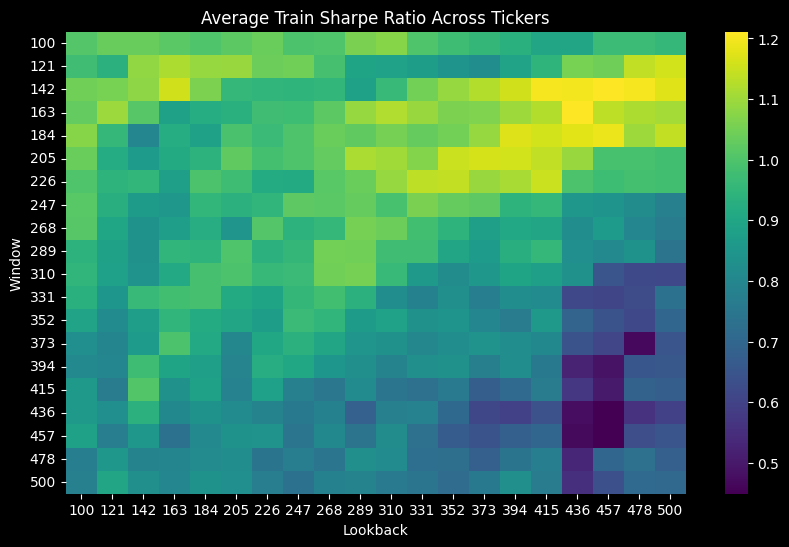

In [ ]:
datas = joblib.load('/Users/leoinv/Documents/CODE/BACKTEST/data/1h.joblib')

train_ratio = 0.7
smooth_windows = np.linspace(100, 500, 20, dtype=int)
norm_lookbacks = np.linspace(100, 500, 20, dtype=int)

# Step 1: Sweep Sharpe across all tickers' train sets
sweep_results = []
i = 0
for ticker, data in datas.items():
    i += 1
    if i > 2:
        break
    if ticker == 'XLMUSDT':
        continue
    data.columns = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']
    data.set_index('Date', inplace=True)
    data = data.dropna()

    if len(data) <= 30000:
        continue

    # Split train/test
    split_idx = int(len(data) * train_ratio)
    train_data = data.iloc[:split_idx]

    for w in smooth_windows:
        for l in norm_lookbacks:
            bt_train = Backtest(train_data, VolatilyTrigger,
                                cash=1000000000, commission=.0005)
            stats = bt_train.run(smooth_window=w, norm_lookback=l)
            sweep_results.append((w, l, stats['Sharpe Ratio'], ticker))

# Step 2: Average Sharpe for each param pair
df_sweep = pd.DataFrame(sweep_results, columns=['Window', 'Lookback', 'Sharpe', 'Ticker'])
avg_sweep = df_sweep.groupby(['Window', 'Lookback'])['Sharpe'].mean().reset_index()

# Step 3: Create heatmap
pivot = avg_sweep.pivot(index='Window', columns='Lookback', values='Sharpe')

plt.style.use('dark_background')
plt.figure(figsize=(10, 6))
sns.heatmap(pivot, cmap='viridis', annot=False)
plt.title("Average Train Sharpe Ratio Across Tickers")
plt.show()


Averaged params → Window: 163, Lookback: 438.000


<ipython-input-4-39964ba1293e>:36: UserWarning: Some trades remain open at the end of backtest. Use `Backtest(..., finalize_trades=True)` to close them and include them in stats.
  stats_train = bt_train.run(smooth_window=best_window, norm_lookback=best_lookback)
<ipython-input-4-39964ba1293e>:42: UserWarning: Some trades remain open at the end of backtest. Use `Backtest(..., finalize_trades=True)` to close them and include them in stats.
  stats_test = bt_test.run(smooth_window=best_window, norm_lookback=best_lookback)
<ipython-input-4-39964ba1293e>:36: UserWarning: Some trades remain open at the end of backtest. Use `Backtest(..., finalize_trades=True)` to close them and include them in stats.
  stats_train = bt_train.run(smooth_window=best_window, norm_lookback=best_lookback)


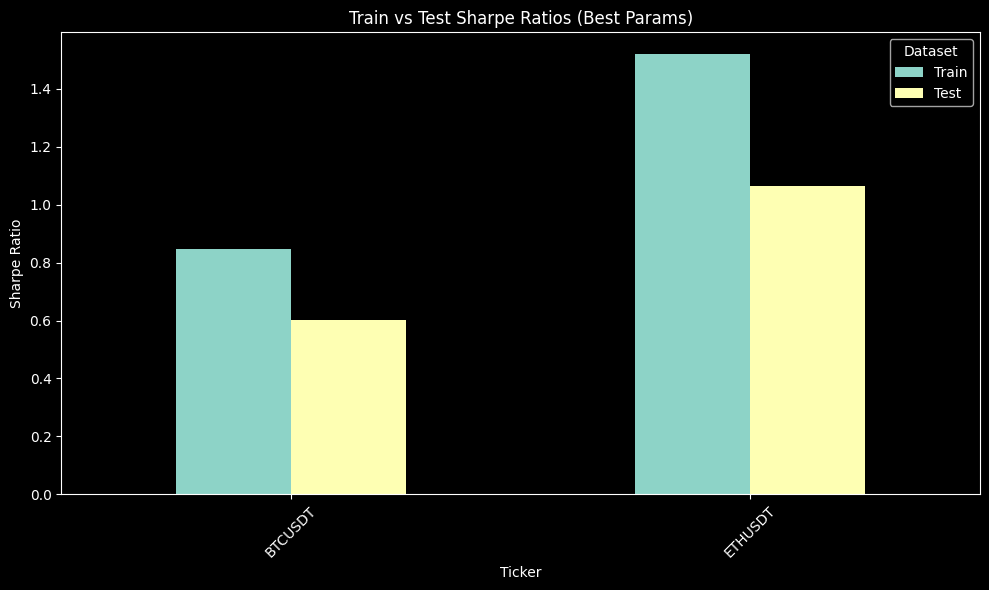

In [ ]:
# Get top rows by Sharpe
top = avg_sweep.nlargest(10, 'Sharpe')

# Average their parameters
best_window = int(top['Window'].mean())
best_lookback = int(top['Lookback'].mean())

print(f"\nAveraged params → Window: {best_window}, Lookback: {best_lookback:.3f}")


# Step 5: Run test set with best params
train_equities = {}
test_equities = {}
train_results = {}
test_results = {}

i = 0
for ticker, data in datas.items():
    if ticker == 'XLMUSDT':
        continue
    i += 1
    if i > 2:
        break

    data = data.dropna()

    if len(data) <= 30000:
        continue

    split_idx = int(len(data) * train_ratio)
    train_data = data.iloc[:split_idx]
    test_data = data.iloc[split_idx:]

    # Train run
    bt_train = Backtest(train_data, VolatilyTrigger, cash=1000000000, commission=.0005)
    stats_train = bt_train.run(smooth_window=best_window, norm_lookback=best_lookback)
    train_results[ticker] = stats_train['Sharpe Ratio']
    train_equities[ticker] = stats_train['_equity_curve']['Equity'].pct_change().cumsum() + 1

    # Test run
    bt_test = Backtest(test_data, VolatilyTrigger, cash=1000000000, commission=.0005)
    stats_test = bt_test.run(smooth_window=best_window, norm_lookback=best_lookback)
    test_results[ticker] = stats_test['Sharpe Ratio']
    test_equities[ticker] = stats_test['_equity_curve']['Equity'].pct_change().cumsum() + 1

# Step 6: Compare Train vs Test Sharpe
df_results = pd.DataFrame({
    "Train": pd.Series(train_results),
    "Test": pd.Series(test_results)
}).dropna(how="all")

df_results.plot(kind='bar', figsize=(10, 6))
plt.title("Train vs Test Sharpe Ratios (Best Params)")
plt.ylabel("Sharpe Ratio")
plt.xlabel("Ticker")
plt.xticks(rotation=45)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

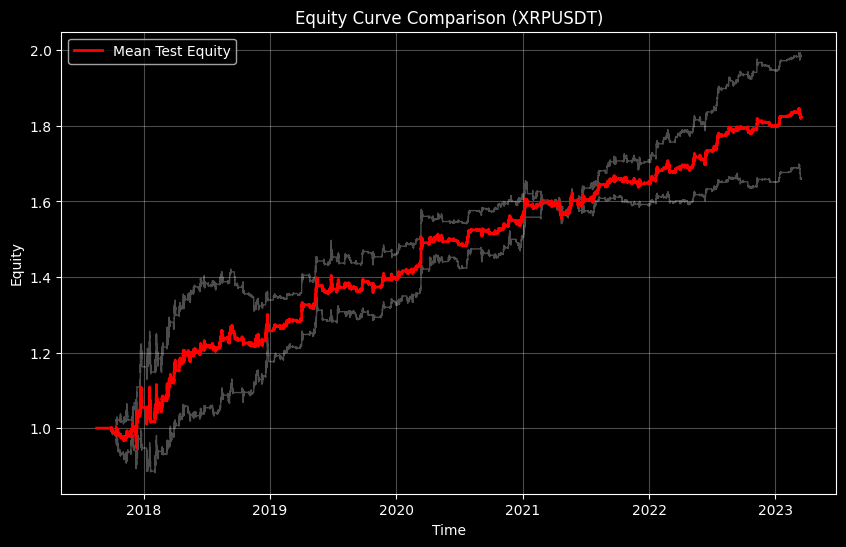

              CAR  Volatility  Sharpe Ratio  Max Drawdown  Calmar Ratio
BTCUSDT  0.095496    0.105224      0.866813     -0.089898      1.062269
ETHUSDT  0.131050    0.106725      1.153890     -0.119531      1.096373

Mean: CAR             0.113273
Volatility      0.105975
Sharpe Ratio    1.010351
Max Drawdown   -0.104715
Calmar Ratio    1.079321
dtype: float64


In [ ]:
df_train = pd.DataFrame(train_equities).dropna().pct_change().cumsum() + 1
df_test = pd.DataFrame(test_equities)

# Calculate mean test equity curve
mean_train_equity = df_train.mean(axis=1)

# Plot
plt.figure(figsize=(10, 6))

# Plot test equities (all in white)
for col in df_train.columns:
    plt.plot(df_train[col], color='white', alpha=0.3, linewidth=1, label='_nolegend_')

# Plot mean of test equities in red
plt.plot(mean_train_equity, color='red', linewidth=2, label='Mean Test Equity')

# Titles and style
plt.title(f"Equity Curve Comparison ({ticker})")
plt.xlabel("Time")
plt.ylabel("Equity")
plt.grid(True, alpha=0.3)
plt.legend()

# Black background for contrast
plt.gca().set_facecolor('black')
plt.show()


from utils import performance_metrics
results = {}
for ticker in df_train.columns:
   results[ticker] = performance_metrics(df_train[ticker], periods_per_year=24* 365)

result_df = pd.DataFrame(results).T
print(result_df)
print(f"\nMean: {result_df.mean()}")

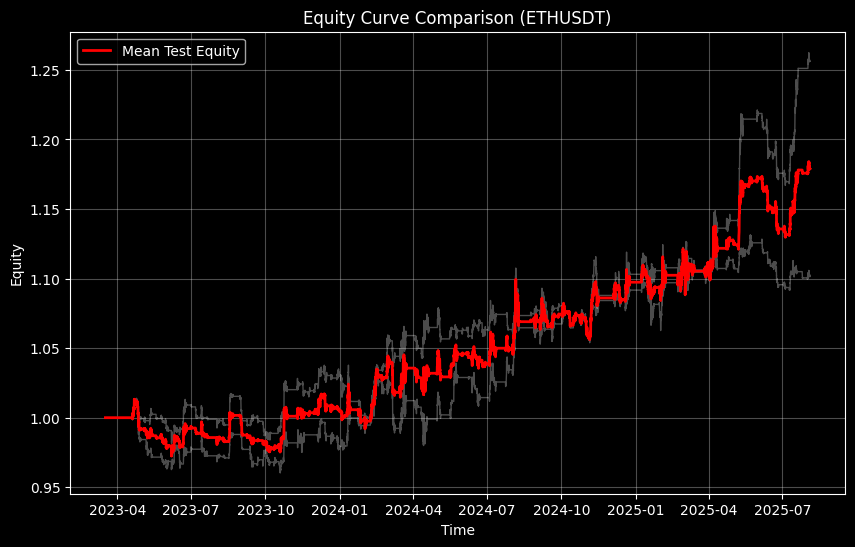

              CAR  Volatility  Sharpe Ratio  Max Drawdown  Calmar Ratio
BTCUSDT  0.041444    0.064279      0.631785      -0.04846      0.855220
ETHUSDT  0.100277    0.082204      1.162550      -0.05253      1.908956

Mean: CAR             0.070860
Volatility      0.073241
Sharpe Ratio    0.897168
Max Drawdown   -0.050495
Calmar Ratio    1.382088
dtype: float64


In [ ]:
# Calculate mean test equity curve
mean_test_equity = df_test.mean(axis=1)

# Plot
plt.figure(figsize=(10, 6))

# Plot test equities (all in white)
for col in df_test.columns:
    plt.plot(df_test[col], color='white', alpha=0.3, linewidth=1, label='_nolegend_')

# Plot mean of test equities in red
plt.plot(mean_test_equity, color='red', linewidth=2, label='Mean Test Equity')

# Titles and style
plt.title(f"Equity Curve Comparison ({ticker})")
plt.xlabel("Time")
plt.ylabel("Equity")
plt.grid(True, alpha=0.3)
plt.legend()

# Black background for contrast
plt.gca().set_facecolor('black')
plt.show()

from utils import performance_metrics
results = {}
for ticker in df_test.columns:
   results[ticker] = performance_metrics(df_test[ticker], periods_per_year=24* 365)


result_df = pd.DataFrame(results).T
print(result_df)
print(f"\nMean: {result_df.mean()}")